# Predicting Heart Disease with Naive Bayes — Helper notebook

This notebook does some variations in relation to the original lab.

In [1]:
# import the libraries we need:
# pandas      -> loading and working with the data table
# numpy       -> number handling and array operations
# matplotlib  -> plotting
# seaborn     -> the correlation heatmap and confusion-matrix heatmap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The variable and functions below allow the correct conversion to LaTeX tables when exporting to PDF with nbconvert.
def correctness_html(value):
    return {
        'Yes': 'color: green; font-weight: bold;',
        'No': 'color: red; font-weight: bold;',
    }.get(value, '')


def correctness_latex(value):
    return {
        'Yes': 'color:{green}; bfseries:;',
        'No': 'color:{red}; bfseries:;',
    }.get(value, '')

def display_table(
    df,
    formats=None,
    latex_formats=None,
    html_style=None,
    latex_style=None,
    style_columns=None,
    hide_index=True,
    fit_to_page=False,
    na_rep=None,
):
    """
    Display a DataFrame as HTML and LaTeX for notebook viewing and PDF export.

    Formats values without modifying the DataFrame. The LaTeX version includes
    alternating row shading, bold headers, and escaped row and column labels.

    Parameters
    ----------
    df : pandas.DataFrame
        Table to display.
    formats : dict, optional
        Column names mapped to format strings or formatting functions.
        Used for both outputs unless overridden by latex_formats.
    latex_formats : dict, optional
        Formatting overrides for LaTeX output. Formatters that generate special
        characters must escape them, for example '%' as r'\\%'.
    html_style : callable, optional
        Function receiving a cell value and returning a CSS style string.
        Return an empty string to leave the cell unchanged.
    latex_style : callable, optional
        Function receiving a cell value and returning a pandas LaTeX style
        string, such as 'color:{green}; bfseries:;'.
    style_columns : list of str, optional
        Columns to which the styling functions apply. If None, apply them
        to all data cells. Callbacks receive original, unformatted values.
    hide_index : bool, default True
        Hide row indexes in both output formats.
    fit_to_page : bool, default False
        Shrink the LaTeX table if it exceeds the PDF text width.
        Does not affect the HTML display.
    na_rep : str or None, default None
        Text displayed for missing values. If None, use the default rendering
        without a custom replacement. Does not modify the underlying data.

    Returns
    -------
    None
        Displays HTML and LaTeX representations through IPython.display.

    Notes
    -----
    The PDF template must load xcolor and colortbl for LaTeX styling,
    and adjustbox when fit_to_page=True.
    Rerun and save the cell outputs before exporting without execution.
    """
    formats = formats or {}
    pdf_formats = {**formats, **(latex_formats or {})}

    html = df.style.format(formats, na_rep=na_rep, escape='html')
    latex = (
        df.style
        .format(pdf_formats, na_rep=na_rep, escape='latex')
        .format_index(escape='latex', axis=0)
        .format_index(escape='latex', axis=1)
    )

    if hide_index:
        html = html.hide(axis='index')
        latex = latex.hide(axis='index')

    # Apply LaTeX row shading and bold labels.
    def stripe_rows(values):
        return [
            'cellcolor:{gray!10}--rwrap;' if i % 2 == 0 else ''
            for i in range(len(values))
        ]

    def style_index(values):
        return [style + 'bfseries:;' for style in stripe_rows(values)]

    latex = (
        latex
        .apply(stripe_rows, axis=0)
        .apply_index(style_index, axis=0)
        .map_index(lambda value: 'bfseries:;', axis=1)
    )

    # Apply caller-supplied styles to selected columns.
    # If style_columns is None, apply to all data cells.
    if html_style is not None:
        html = html.map(html_style, subset=style_columns)

    if latex_style is not None:
        latex = latex.map(latex_style, subset=style_columns)

    latex_output = latex.to_latex()

    if fit_to_page:
        latex_output = (
            r"\begin{adjustbox}{max width=\linewidth}" "\n"
            + latex_output
            + "\n" r"\end{adjustbox}"
        )

    display({
        'text/html': html.to_html(),
        'text/latex': latex_output,
    }, raw=True)

In [2]:
# display_estimator: show a scikit-learn model as the interactive HTML diagram in the notebook,
# and as an equivalent boxed LaTeX diagram when exporting to PDF with nbconvert
# (nbconvert cannot render the HTML diagram and would otherwise fall back to plain text).
import inspect
from sklearn.base import BaseEstimator
from sklearn.pipeline import Pipeline
from sklearn.utils import estimator_html_repr


def _tex(text):
    """Escape LaTeX special characters."""
    rep = {'\\': r'\textbackslash{}', '&': r'\&', '%': r'\%', '$': r'\$', '#': r'\#',
           '_': r'\_', '{': r'\{', '}': r'\}', '~': r'\textasciitilde{}', '^': r'\textasciicircum{}'}
    return ''.join(rep.get(ch, ch) for ch in str(text))


def _changed_params(est):
    """Parameters that differ from their defaults (nested estimators are drawn as boxes instead)."""
    defaults = inspect.signature(type(est).__init__).parameters
    shown = []
    for name, value in est.get_params(deep=False).items():
        if name == 'steps' or isinstance(value, BaseEstimator):
            continue
        default = defaults[name].default if name in defaults else inspect.Parameter.empty
        try:
            if value is default or value == default:
                continue
        except Exception:            # e.g. arrays, where == is element-wise
            pass
        text = value.__name__ if callable(value) and hasattr(value, '__name__') else repr(value)
        shown.append(f"{name}={text}")
    return shown


def _estimator_latex(est, name=None, depth=0):
    """Nested boxes: one per estimator, pipeline steps joined by arrows."""
    fill = ['gray!12', 'white', 'blue!6'][depth % 3]
    if isinstance(est, str):         # e.g. 'passthrough' / 'drop' pipeline steps
        return r'\fcolorbox{gray}{' + fill + r'}{\texttt{' + _tex(f"{name}: {est}") + '}}'
    title = type(est).__name__ if name is None else f"{name}: {type(est).__name__}"
    rows = [r'\textbf{' + _tex(title) + '}']
    rows += [r'\footnotesize\texttt{' + _tex(p) + '}' for p in _changed_params(est)]
    if isinstance(est, Pipeline):
        children = [_estimator_latex(step, step_name, depth + 1) for step_name, step in est.steps]
        rows.append(r'\begin{tabular}{c}' + r' \\ $\downarrow$ \\ '.join(children) + r'\end{tabular}')
    else:
        nested = [(n, v) for n, v in est.get_params(deep=False).items() if isinstance(v, BaseEstimator)]
        if nested:
            children = [_estimator_latex(v, n, depth + 1) for n, v in nested]
            rows.append(r'\begin{tabular}{c}' + r' \\ '.join(children) + r'\end{tabular}')
    return r'\fcolorbox{gray}{' + fill + r'}{\begin{tabular}{c}' + r' \\ '.join(rows) + r'\end{tabular}}'


def display_estimator(est):
    """Display a scikit-learn estimator for both notebook viewing (HTML) and PDF export (LaTeX)."""
    display({
        'text/html': estimator_html_repr(est),
        'text/latex': r'\begin{center}' + _estimator_latex(est) + r'\end{center}',
        'text/plain': repr(est),
    }, raw=True)

First we drop the `education` column, as it will not be used in the analysis and contains `NaN` values. Then we remove rows with `NaN` values in any column **except `glucose`**. Glucose has by far the most missing values, so instead of discarding those patients we impute them later, inside the machine-learning pipeline.

In [3]:
# read the Framingham heart study data - 4,238 patients
raw_data = pd.read_csv('data/framingham.csv')

print(f"\nThe dataset contains {raw_data.shape[0]} rows and {raw_data.shape[1]} columns")

#print("Showing how many rows have missing values per column")
#print(df.isnull().sum())                                # how many missing values in each column?
missing_values = (
    raw_data.isna().sum()
    .rename_axis('Column')
    .reset_index(name='Sum of missing values')
)

display_table(missing_values)

df = raw_data.drop(['education'], axis=1)            # keep the feature set to clinical and behavioural measures
#df.dropna(axis=0, inplace=True)                         # drop rows with any missing value
df.dropna(subset=df.columns.drop('glucose'), inplace=True) # drop rows with any missing value, except the glucose column which is important
df.rename(columns={'male':'sex_male'}, inplace=True)    # clearer column name
#print(df.shape)                                         # rows and columns after cleaning: (3656, 15)
print(f"\nThe dataset after the changes contains {df.shape[0]} rows and {df.shape[1]} columns")
print("\nShowing the first rows")
df.head()                                               # first look at the cleaned data


The dataset contains 4238 rows and 16 columns


Column,Sum of missing values
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50



The dataset after the changes contains 4088 rows and 15 columns

Showing the first rows


,sex_male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


Looking at the Glucose values

In [4]:
print("Glucose levels for all patients, those with no CHD and those with CHD")
glucose_summary = pd.concat({
    'All cases': raw_data['glucose'].describe(),
    'No CHD (0)': raw_data.loc[
        raw_data['TenYearCHD'] == 0, 'glucose'
    ].describe(),
    'CHD (1)': raw_data.loc[
        raw_data['TenYearCHD'] == 1, 'glucose'
    ].describe(),
}, axis=1)

display(glucose_summary)

Glucose levels for all patients, those with no CHD and those with CHD


,All cases,No CHD (0),CHD (1)
count,3850.000000,3256.000000,594.000000
mean,81.966753,80.682125,89.008418
std,23.959998,18.968192,41.140752
min,40.000000,40.000000,40.000000
25%,71.000000,71.000000,72.000000
50%,78.000000,78.000000,79.000000
75%,87.000000,86.000000,90.000000
max,394.000000,386.000000,394.000000


In [5]:
groups = {
    'All cases': raw_data['glucose'],
    'No CHD (0)': raw_data.loc[raw_data['TenYearCHD'] == 0, 'glucose'],
    'CHD (1)': raw_data.loc[raw_data['TenYearCHD'] == 1, 'glucose'],
}

glucose_summary = pd.concat(
    {name: s.describe() for name, s in groups.items()}, axis=1
)
glucose_summary.loc['missing values'] = [s.isna().sum() for s in groups.values()]
glucose_summary.loc['missing values %'] = [s.isna().mean() * 100 for s in groups.values()]

display(glucose_summary)

,All cases,No CHD (0),CHD (1)
count,3850.000000,3256.000000,594.000000
mean,81.966753,80.682125,89.008418
std,23.959998,18.968192,41.140752
min,40.000000,40.000000,40.000000
25%,71.000000,71.000000,72.000000
50%,78.000000,78.000000,79.000000
75%,87.000000,86.000000,90.000000
max,394.000000,386.000000,394.000000
missing values,388.000000,338.000000,50.000000
missing values %,9.155262,9.404563,7.763975


### Why we should not impute glucose using `TenYearCHD`

`TenYearCHD` is the **target we want to predict**, so we must not use it to decide how to fill missing input values.

For example, suppose we calculate separate glucose means for individuals with and without a CHD event. Filling each missing glucose value using its true CHD group's mean would allow the answer to influence the model's inputs. This is **target leakage**.

It creates two problems:

1. **The procedure cannot be applied to new patients.** Their future CHD outcome is unknown—that is precisely what the model is supposed to predict. We would not know which group's mean to use.
2. **Evaluation could become misleading.** If validation or test labels determine the imputed values, those inputs contain information about the answers. Performance would no longer represent predictions made without knowing the outcomes.

Even calculating the two group means from training data only does not solve the problem: choosing between them for a new patient still requires knowing the target.

### Appropriate approach

Impute glucose using only **input features** that are available at prediction time, never the target, and learn the imputation from the **training set only**. The simplest option is a single glucose mean or median from the training data. In this notebook we use an **iterative imputer**, which predicts missing glucose from the patient's other features (notably `diabetes`).

The imputer is placed inside a pipeline, so during cross-validation each round learns its filling values from that round's training folds only, and the test set is filled using what was learned from the training set.

**Grouping glucose by `TenYearCHD` is useful for exploratory analysis; using the true target to fill prediction inputs is not.**

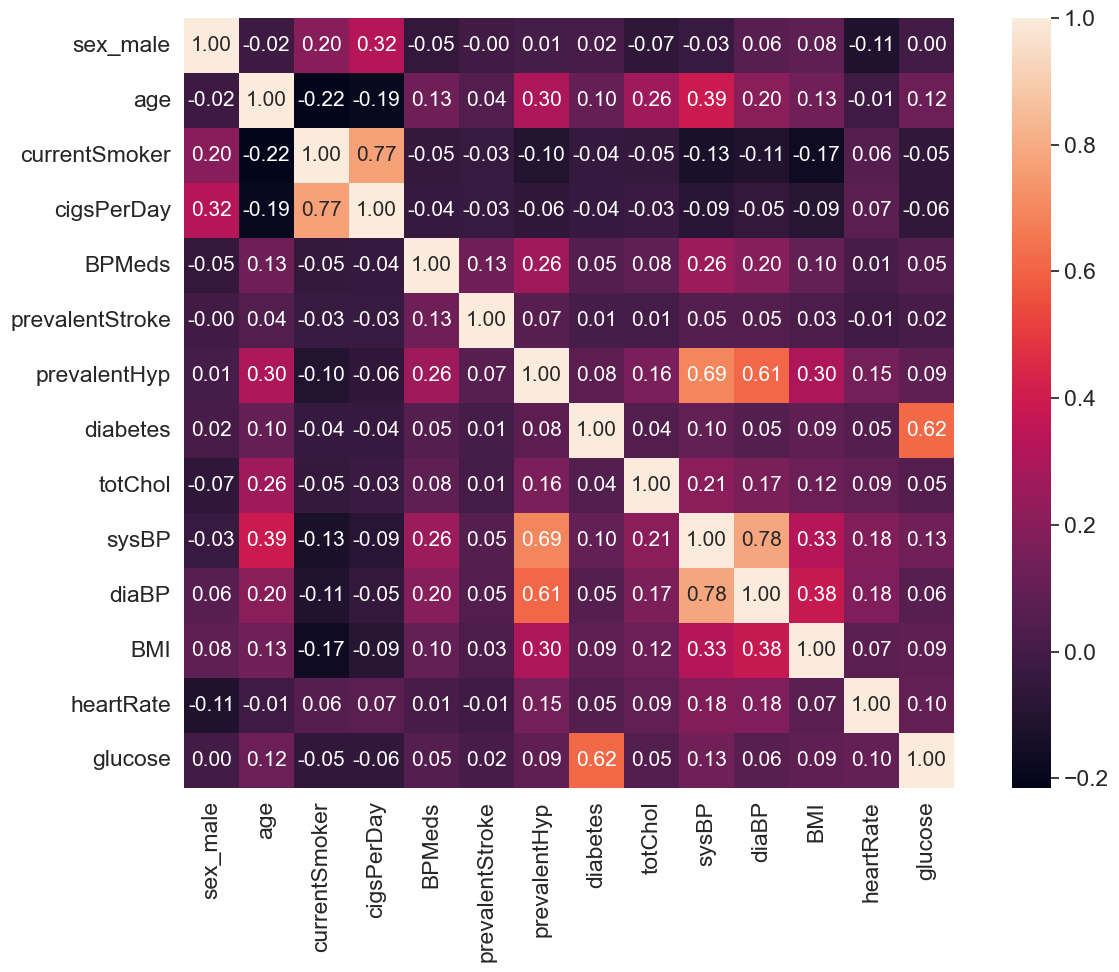

In [6]:
# one styling call: whitegrid background, notebook sizing, larger fonts
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.5)

# the 14 feature columns we will check for correlation
cols = ['sex_male','age', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp',
        'diabetes','totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate','glucose']

# correlation between every pair of features (a 14 x 14 grid of values)
#cm = np.corrcoef(df[cols].values.T)
cm = df[cols].corr().values

# draw it as a heatmap: annot=True prints each value, fmt='.2f' = 2 decimal places
f, ax = plt.subplots(figsize=(15,10))
heatMap = sns.heatmap(cm, cbar=True, annot=True,square=True, fmt='.2f', annot_kws={'size' : 15}, yticklabels=cols,
xticklabels=cols)
plt.show()

## Removing highly correlated features

In [7]:
debug_mode = False
# scan the correlation matrix and collect the name of any feature whose
# correlation with an earlier feature is stronger than the threshold -
# those are the columns we will drop before fitting Naive Bayes
def correlation(dataset, threshold):
    col_corr = set()                                    # Set of all the names of correlated columns
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)): # The row
        if debug_mode:
            print(f"Processing feature {i}: {corr_matrix.columns[i]}")
            if corr_matrix.columns[i] in ['cigsPerDay', 'diaBP']:
                print("Feature of interest for debugging found")
        for j in range(i): # The column
            if abs(corr_matrix.iloc[i, j]) > threshold: # we are interested in absolute coeff value
                colname = corr_matrix.columns[i]        # getting the name of column
                col_corr.add(colname)
                print(f"Feature '{colname}' is highly correlated with feature '{corr_matrix.columns[j]}'")
    return col_corr

# run it on our 14 features with a 0.7 threshold and show what it found
corr_features = correlation(df[cols], 0.7)
print(f"The columns with high correlation are: {corr_features}")

Feature 'cigsPerDay' is highly correlated with feature 'currentSmoker'
Feature 'diaBP' is highly correlated with feature 'sysBP'
The columns with high correlation are: {'diaBP', 'cigsPerDay'}


In [8]:
df.drop(corr_features,axis=1, inplace=True)
df.head()

,sex_male,age,currentSmoker,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,0,0.0,0,0,0,195.0,106.0,26.97,80.0,77.0,0
1,0,46,0,0.0,0,0,0,250.0,121.0,28.73,95.0,76.0,0
2,1,48,1,0.0,0,0,0,245.0,127.5,25.34,75.0,70.0,0
3,0,61,1,0.0,0,1,0,225.0,150.0,28.58,65.0,103.0,1
4,0,46,1,0.0,0,0,0,285.0,130.0,23.10,85.0,85.0,0


## Machine Learning

In [9]:
from sklearn.model_selection import train_test_split, cross_validate, TunedThresholdClassifierCV
#from sklearn.preprocessing import StandardScaler # No longer required
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
#from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB

In [10]:
# x = every column except the last (the features)
# y = the last column only (TenYearCHD — the value we want to predict)
x = df.iloc[:, :-1]          # keep as a DataFrame: later steps refer to columns by name (e.g. 'diabetes')
y = df.iloc[:, -1].values    # .values gives a plain NumPy array (later cells call y_test.reshape)

# separate dataset into train (70%) and test (30%)
# random_state=0 makes the split reproducible — same rows every run
# stratify=y keeps the CHD rate (~15%) the same in both sets

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0, stratify=y)

# confirm the split: (rows, features) for each set
split_summary = pd.DataFrame({
    'Dataset': ['Training', 'Test'],
    'Rows': [X_train.shape[0], X_test.shape[0]],
    'Features': [X_train.shape[1], X_test.shape[1]],
})

display_table(
    split_summary,
    formats={'Rows': '{:,}', 'Features': '{:d}'},
)

Dataset,Rows,Features
Training,"2,861",12
Test,"1,227",12


### No feature scaling

The original lab standardised the features with `StandardScaler`. Gaussian Naive Bayes doesn't need this: it fits a separate mean and standard deviation for each feature and class, so features measured on large scales (e.g. `totChol`) don't dominate small ones (e.g. `sex_male`). Scaling matters for distance-based models such as KNN, not for Naive Bayes. Removing it also keeps `X_train` as a DataFrame, so later steps can refer to columns by name.

Removed:

```python
# standardise the features: rescale each column to mean 0, standard deviation 1,
# so big-number features (e.g. totChol ~240) don't drown out small ones (e.g. sex_male 0/1)

sc = StandardScaler()

# fit_transform on TRAIN: learn each column's mean and std, then rescale
X_train = sc.fit_transform(X_train)

# transform only on TEST: reuse the means and stds learned from the training set
# (never fit on the test set — that would leak test information into the model)
X_test = sc.transform(X_test)
```

### Imputing missing glucose values

After cleaning, about 8% of patients (339 of 4,088) have no `glucose` reading: 239 in the training set and 100 in the test set. Instead of dropping those rows, we estimate the missing values with an **iterative imputer**. It predicts each missing value from the patient's other features using a regression model. This suits glucose because it is strongly correlated with `diabetes` (r ≈ 0.62): a diabetic patient gets a higher estimate than a non-diabetic one, which a single overall mean or median would not capture.

The imputer and the Naive Bayes classifier are chained in a **pipeline**:

1. `fit(X_train, y_train)`: the imputer learns its regression models from the **training set only**, fills in the training NaNs, and then the classifier is trained.
2. `predict(X_test)`: the test set's NaNs are filled using what the imputer learned from the training data, and then the classifier makes its predictions.

Fitting the imputer on the training data only prevents **data leakage**. If the test set influenced how values are imputed, the test score would be overly optimistic.

### Should we also drop `diabetes`?

`glucose` and `diabetes` are correlated (r ≈ 0.62), below our 0.7 threshold, but Naive Bayes may still count their shared evidence twice. We keep `diabetes` for the imputer (it helps estimate missing glucose) and compare, with 5-fold cross-validation on the training set, a model that keeps it against one that drops it **after** imputation.

In [11]:
# build a pipeline: impute missing values -> (optionally) drop diabetes -> Gaussian Naive Bayes
def drop_diabetes_col(X):
    return X.drop(columns='diabetes')

def make_model(drop_diabetes):
    # set_output(transform='pandas') keeps column names after imputation, so 'diabetes' can be dropped by name
    steps = [('imputer', IterativeImputer(random_state=0).set_output(transform='pandas'))]
    if drop_diabetes:
        # remove diabetes AFTER it has been used to impute glucose
        steps.append(('drop', FunctionTransformer(drop_diabetes_col)))
    steps.append(('nb', GaussianNB()))
    return Pipeline(steps)

# choose the metric that decides the winner (F1 for CHD balances catching cases vs. false alarms)
decision_metric = 'f1'

# 5-fold cross-validation on the training set only (the test set stays unseen)
results = {}
for drop in [False, True]:
    scores = cross_validate(make_model(drop), X_train, y_train, cv=5,
                            scoring=['recall', 'precision', 'f1', 'roc_auc'])
    results[drop] = {k[5:]: v.mean() for k, v in scores.items() if k.startswith('test_')}

cv_results = pd.DataFrame(results).T
cv_results.index = ['Keep diabetes', 'Drop diabetes']

display_table(
    cv_results.reset_index(names='Model'),
    formats={c: '{:.3f}' for c in cv_results.columns},
)

# True if dropping diabetes scored strictly better; on a tie we keep it (fewer changes to the data)
best_drop_diabetes = results[True][decision_metric] > results[False][decision_metric]
print(f"Best on {decision_metric}: {'drop' if best_drop_diabetes else 'keep'} diabetes")

Model,recall,precision,f1,roc_auc
Keep diabetes,0.178,0.336,0.232,0.711
Drop diabetes,0.182,0.362,0.242,0.715


Best on f1: drop diabetes


### Tuning the decision threshold

By default, `predict()` labels a patient as CHD when the predicted probability is above 0.5. With only ~15% CHD cases this rarely happens, so most CHD patients are missed. `TunedThresholdClassifierCV` searches for the threshold that maximises F1 for CHD, using 5-fold cross-validation on the **training set only**, then refits the model on all training data.

The selected threshold (printed below) is very low. This does not mean a "2% risk" cut-off. Naive Bayes probabilities are poorly calibrated: because correlated features are treated as independent, overlapping evidence is multiplied together and the probabilities are pushed towards 0 or 1. The model's *ranking* of patients is still useful (cross-validated ROC AUC ≈ 0.71), so the threshold should be read as a cut-off on that ranking, not as a real risk.

The code below uses `TunedThresholdClassifierCV`. The same thing can be done manually:

```python
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

# out-of-fold CHD probabilities for every training patient (each predicted by a model that didn't see it)
train_proba = cross_val_predict(make_model(best_drop_diabetes), X_train, y_train,
                                cv=5, method='predict_proba')[:, 1]

thresholds = np.arange(0.05, 0.95, 0.05)
f1_scores = [f1_score(y_train, (train_proba >= t).astype(int)) for t in thresholds]

best_threshold = thresholds[int(np.argmax(f1_scores))]
print(f"Best threshold on cross-validated F1: {best_threshold:.2f}")

display(pd.DataFrame({'threshold': thresholds, 'CV F1 (CHD)': f1_scores}).round(3))
```

In [12]:
# final model: the pipeline chosen above (keep or drop diabetes), wrapped so its decision threshold is tuned
classifier = TunedThresholdClassifierCV(make_model(best_drop_diabetes), scoring='f1', cv=5)

# interactive diagram in the notebook, boxed LaTeX diagram in the PDF (see display_estimator in the setup cells)
display_estimator(classifier)

TunedThresholdClassifierCV(cv=5,
                           estimator=Pipeline(steps=[('imputer',
                                                      IterativeImputer(random_state=0)),
                                                     ('drop',
                                                      FunctionTransformer(func=<function drop_diabetes_col at 0x701615f4c0>)),
                                                     ('nb', GaussianNB())]),
                           scoring='f1')

In [13]:
# fit does two things, both on the training data only:
# 1. tunes the threshold: 5-fold CV finds the probability cut-off that maximises F1 for CHD
# 2. refits the pipeline on all training data: the imputer learns to fill NaNs, then Naive Bayes
#    learns how common each class is plus each feature's mean and spread (a bell curve per feature).
#    To predict, it asks: is this patient's CHD probability above the tuned threshold?
classifier.fit(X_train, y_train)
print(f"The tuned threshold is {classifier.best_threshold_:.4f}")

The tuned threshold is 0.0208


In [14]:
# ask the fitted model to predict CHD (1) or no CHD (0) for every test patient
y_pred = classifier.predict(X_test) # uses the tuned threshold

# show the predictions and the actual answers side by side:
# left column = predicted, right column = actual
# (reshape turns each 1-D array into a column; concatenate glues the columns together)
side_by_side_matrix = np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1)
#print(side_by_side_matrix)
print(f"The side-by-side matrix has {side_by_side_matrix.shape[0]} rows and {side_by_side_matrix.shape[1]} columns.")

predicted = np.asarray(y_pred).ravel()
actual = np.asarray(y_test).ravel()

comparison = pd.DataFrame({
    'Test case': np.arange(1, len(actual) + 1),
    'Predicted CHD': predicted,
    'Actual CHD': actual,
    'Correct?': np.where(predicted == actual, 'Yes', 'No'),
})

print(f"The side-by-side comparison matrix has {comparison.shape[0]} rows and {comparison.shape[1]} columns.")

display_table(
    comparison.head(20),
    html_style=correctness_html,
    latex_style=correctness_latex,
    style_columns=['Correct?'],
)

The side-by-side matrix has 1227 rows and 2 columns.
The side-by-side comparison matrix has 1227 rows and 4 columns.


Test case,Predicted CHD,Actual CHD,Correct?
1,0,0,Yes
2,0,0,Yes
3,1,1,Yes
4,0,0,Yes
5,1,0,No
6,0,0,Yes
7,0,0,Yes
8,1,0,No
9,0,0,Yes
10,0,1,No


In [15]:
# count how the predictions line up with the actual answers

# rows = actual, columns = predicted:
# [[ true negatives    false positives ]
#  [ false negatives   true positives  ]]
cm = confusion_matrix(y_test, y_pred)
print(cm)

# accuracy = (true negatives + true positives) / all test patients
accuracy_score(y_test, y_pred)

[[644 400]
 [ 65 118]]


0.6210268948655256

<Axes: >

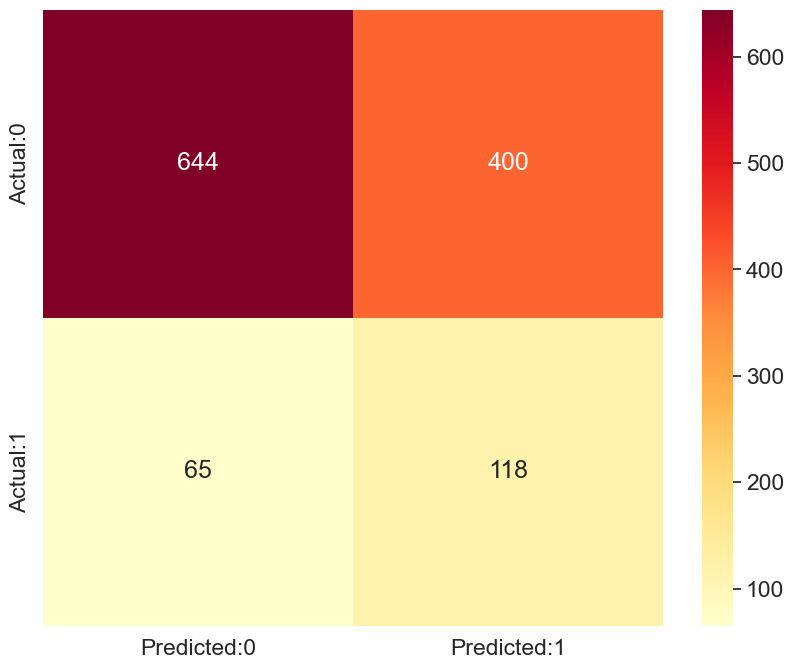

In [16]:
# rebuild the confusion matrix (same numbers as the previous cell)
cmatrix = confusion_matrix(y_test, y_pred)

# wrap it in a DataFrame so the rows and columns carry readable labels
conf_matrix = pd.DataFrame(data=cmatrix, columns=['Predicted:0','Predicted:1'], index=['Actual:0','Actual:1'])

# draw it as a heatmap: annot=True prints the count inside each square,
# fmt='d' shows the counts as whole numbers, cmap is the colour scale (yellow = low, red = high)
plt.figure(figsize = (10,8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='YlOrRd')

In [17]:
# the classification report scores each class separately:
#   precision = of the patients the model flagged as this class, how many really were
#   recall    = of the patients who really ARE this class, how many the model caught
#   f1-score  = the balance of precision and recall (their harmonic mean)
#   support   = how many test patients are actually in this class

# target_names swaps the 0/1 labels for readable ones in the printout
print(classification_report(y_test, y_pred, target_names=['No CHD (0)', 'CHD (1)']))

              precision    recall  f1-score   support

  No CHD (0)       0.91      0.62      0.73      1044
     CHD (1)       0.23      0.64      0.34       183

    accuracy                           0.62      1227
   macro avg       0.57      0.63      0.54      1227
weighted avg       0.81      0.62      0.68      1227



## Conclusions

### What changed compared with the original lab

| Step | Original lab | This notebook |
|---|---|---|
| Missing values | Dropped every incomplete row (3,656 of 4,238 patients kept) | Dropped `education`, imputed missing `glucose`, dropped rows missing other values (**4,088 kept**) |
| Glucose imputation | — | `IterativeImputer` inside a pipeline, fitted on training data only |
| Correlated features | Dropped `cigsPerDay` and `diaBP` (r > 0.7) | Same, plus `diabetes` dropped **after** it has been used to impute glucose (chosen by cross-validation) |
| Feature scaling | `StandardScaler` | Removed: Gaussian Naive Bayes doesn't need it |
| Decision threshold | 0.5 (default) | Tuned with 5-fold CV on the training set to maximise CHD F1 (≈ 0.021) |

### Results on the test set (1,227 patients, 183 with CHD)

| Model | CHD precision | CHD recall | CHD F1 | Accuracy | CHD caught | False alarms |
|---|---:|---:|---:|---:|---:|---:|
| Imputed, keep `diabetes`, threshold 0.5 | 0.38 | 0.20 | 0.26 | 0.83 | 36 | 58 |
| Imputed, drop `diabetes`, threshold 0.5 | 0.41 | 0.21 | 0.28 | 0.84 | 38 | 55 |
| **Imputed, drop `diabetes`, tuned threshold** | **0.23** | **0.64** | **0.34** | **0.62** | **118** | **400** |

For reference, the original lab scored CHD precision 0.38, recall 0.18, F1 0.24 and accuracy 0.83. It used a different, smaller test set (1,097 patients), so those figures are not directly comparable.

### What did we learn?

- **Imputing beats discarding.** Imputing glucose kept 339 patients who would otherwise have been dropped (about 8% of the cleaned data), and performance did not get worse.
- **Impute from features, never from the target.** Glucose was imputed from the other inputs (mainly `diabetes`), never from `TenYearCHD`, and the imputer was fitted on the training data only to avoid leakage.
- **Dropping `diabetes` helped only a little.** In cross-validation, CHD F1 rose from 0.232 to 0.242, consistent with Naive Bayes double-counting the evidence it shares with glucose. With fewer than 200 CHD cases in the test set, a difference of 2 patients caught is within normal variation, so this is a small improvement at most.
- **The threshold matters far more than the features.** At the default 0.5 threshold the model caught only about 1 in 5 CHD patients. Tuning the threshold raised recall from 0.21 to 0.64 (38 to 118 patients caught), at the cost of 345 more false alarms and accuracy falling from 0.84 to 0.62.
- **Accuracy is misleading on imbalanced data.** The model with the best accuracy (0.84) misses 79% of CHD cases. With ~15% CHD prevalence, predicting "no CHD" for everyone would already score about 85%.
- **Naive Bayes ranks patients reasonably but its probabilities are not real risks.** The ROC AUC is about 0.71 in every version, so the models order patients by risk equally well. The tuned threshold of ≈ 0.02 reflects poorly calibrated probabilities, not a 2% risk.

### Limitations and next steps

- **The right threshold is a clinical decision.** F1 weights missed cases and false alarms equally. If a missed CHD case is much worse than an unnecessary follow-up, choose the threshold for a target recall instead and report the resulting precision.
- **The improvements come from the trade-off, not a better model.** AUC did not change. Improving the ranking itself would need different features or a different model (e.g. logistic regression), ideally with calibrated probabilities (`CalibratedClassifierCV`).
- **The results come from one train/test split.** Repeating the evaluation over several random splits, or reporting cross-validated scores with their spread, would show how stable these numbers are.